In [1]:
import os
from google.colab import userdata

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia --unzip -p ./chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [02:15<00:00, 18.1MB/s]



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as sns
import seaborn as sns
import random
import plotly
import plotly.graph_objs as go
import plotly.express as px
import plotly.express as px
from plotly.offline import init_notebook_mode, plot, iplot
import glob

In [3]:
directory = '/content/chest-xray-pneumonia/chest_xray/chest_xray'

In [4]:
train_df = glob.glob('/content/chest-xray-pneumonia/chest_xray/train/**/*.jpeg')

In [5]:
test_df = glob.glob('/content/chest-xray-pneumonia/chest_xray/test/**/*.jpeg')

In [6]:
val_df = glob.glob('/content/chest-xray-pneumonia/chest_xray/val/**/*.jpeg')

In [7]:
from termcolor import colored
print(colored('The datasets were succesfullly loaded...', color = 'green', attrs=['bold', 'dark']))

The datasets were succesfullly loaded...


In [8]:
train_df[:5], test_df[:5]

(['/content/chest-xray-pneumonia/chest_xray/train/NORMAL/NORMAL2-IM-1135-0001.jpeg',
  '/content/chest-xray-pneumonia/chest_xray/train/NORMAL/NORMAL2-IM-0992-0001.jpeg',
  '/content/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0265-0001.jpeg',
  '/content/chest-xray-pneumonia/chest_xray/train/NORMAL/NORMAL2-IM-1111-0001.jpeg',
  '/content/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0685-0001.jpeg'],
 ['/content/chest-xray-pneumonia/chest_xray/test/NORMAL/IM-0027-0001.jpeg',
  '/content/chest-xray-pneumonia/chest_xray/test/NORMAL/NORMAL2-IM-0105-0001.jpeg',
  '/content/chest-xray-pneumonia/chest_xray/test/NORMAL/IM-0043-0001.jpeg',
  '/content/chest-xray-pneumonia/chest_xray/test/NORMAL/NORMAL2-IM-0256-0001.jpeg',
  '/content/chest-xray-pneumonia/chest_xray/test/NORMAL/NORMAL2-IM-0312-0001.jpeg'])

In [9]:
print('There is {} images in the training datasets'.format(len(train_df)))
print('There is {} images in the test datasets'.format(len(test_df)))
print('There is {} images in the validation datasets'.format(len(val_df)))

There is 5216 images in the training datasets
There is 624 images in the test datasets
There is 16 images in the validation datasets


In [10]:
datasets, pneumonia_lung, normal_lung = ['train', 'test', 'val'], [], []
for i in datasets:
  path = os.path.join(directory, i)
  normal = glob.glob(os.path.join(path, 'NORMAL/*.jpeg'))
  pneumonia = glob.glob(os.path.join(path, 'PNEUMONIA/*.jpeg'))
  normal_lung.extend(normal),
  pneumonia_lung.extend(pneumonia)
print('The number of pneumonia images is {}'.format(len(pneumonia_lung)))
print('The number of normal images is {}'.format(len(normal_lung)))

The number of pneumonia images is 4273
The number of normal images is 1583


In [11]:
random.shuffle(normal_lung)
random.shuffle(pneumonia_lung)
images = normal[:50] + pneumonia_lung[:50]
images[:10]

['/content/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL/NORMAL2-IM-1430-0001.jpeg',
 '/content/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL/NORMAL2-IM-1436-0001.jpeg',
 '/content/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL/NORMAL2-IM-1437-0001.jpeg',
 '/content/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL/NORMAL2-IM-1431-0001.jpeg',
 '/content/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL/NORMAL2-IM-1438-0001.jpeg',
 '/content/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL/NORMAL2-IM-1442-0001.jpeg',
 '/content/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL/NORMAL2-IM-1440-0001.jpeg',
 '/content/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL/NORMAL2-IM-1427-0001.jpeg',
 '/content/chest-xray-pneumonia/chest_xray/chest_xray/train/PNEUMONIA/person258_bacteria_1216.jpeg',
 '/content/chest-xray-pneumonia/chest_xray/chest_xray/train/PNEUMONIA/person918_bacteria_2843.jpeg']

Normal


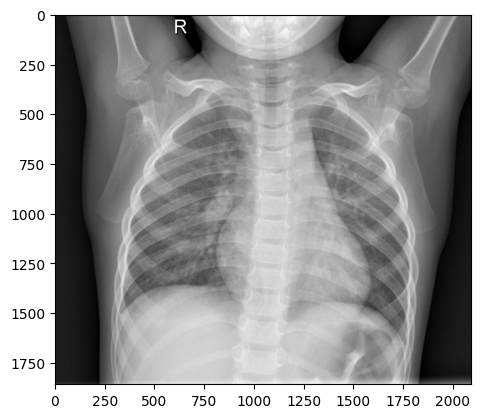

In [12]:
import tensorflow
from tensorflow.keras.preprocessing.image import load_img, array_to_img, img_to_array
normal_lungs_images = load_img('/content/chest-xray-pneumonia/chest_xray/chest_xray/train/NORMAL/IM-0115-0001.jpeg')
print('Normal')
plt.imshow(normal_lungs_images)
plt.show()

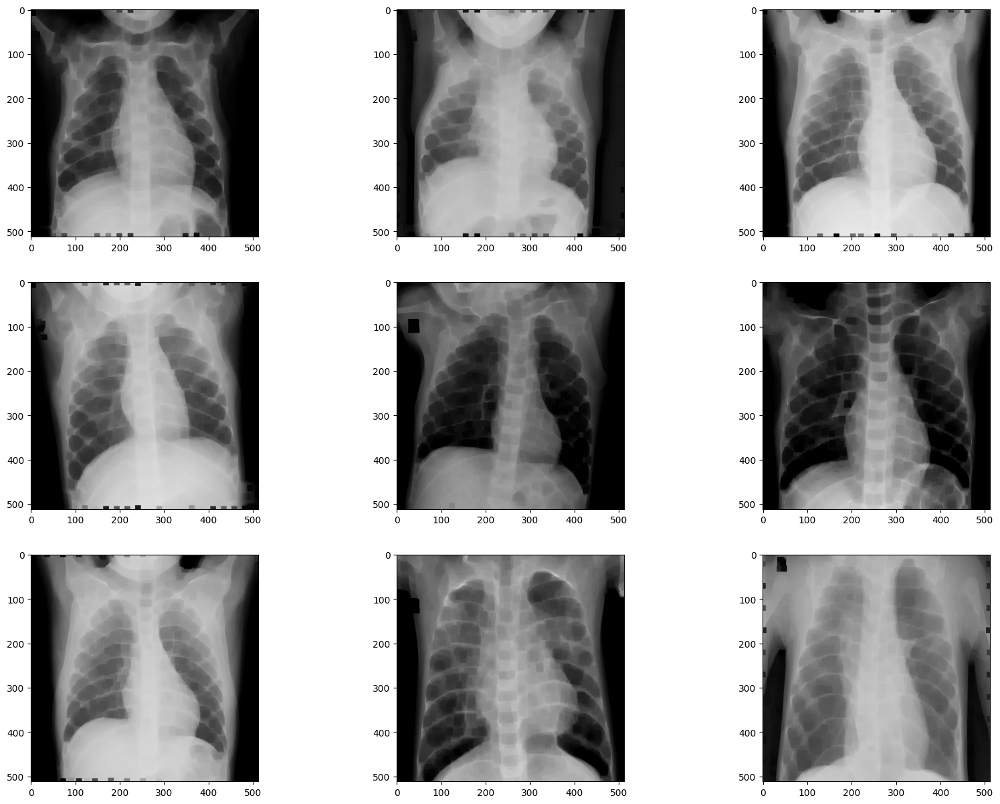

In [13]:
import cv2
import numpy as np
fig = plt.figure(figsize = (20, 15))
columns, rows = 3, 3
for i in range(1, 10):
  img = cv2.imread(images[i])
  img = cv2.resize(img, (512, 512))
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  kernel = np.ones((5, 5), np.uint8)
  image_erosion = cv2.erode(img,kernel, iterations = 3)
  fig.add_subplot(rows, columns, i)
  plt.imshow(image_erosion)

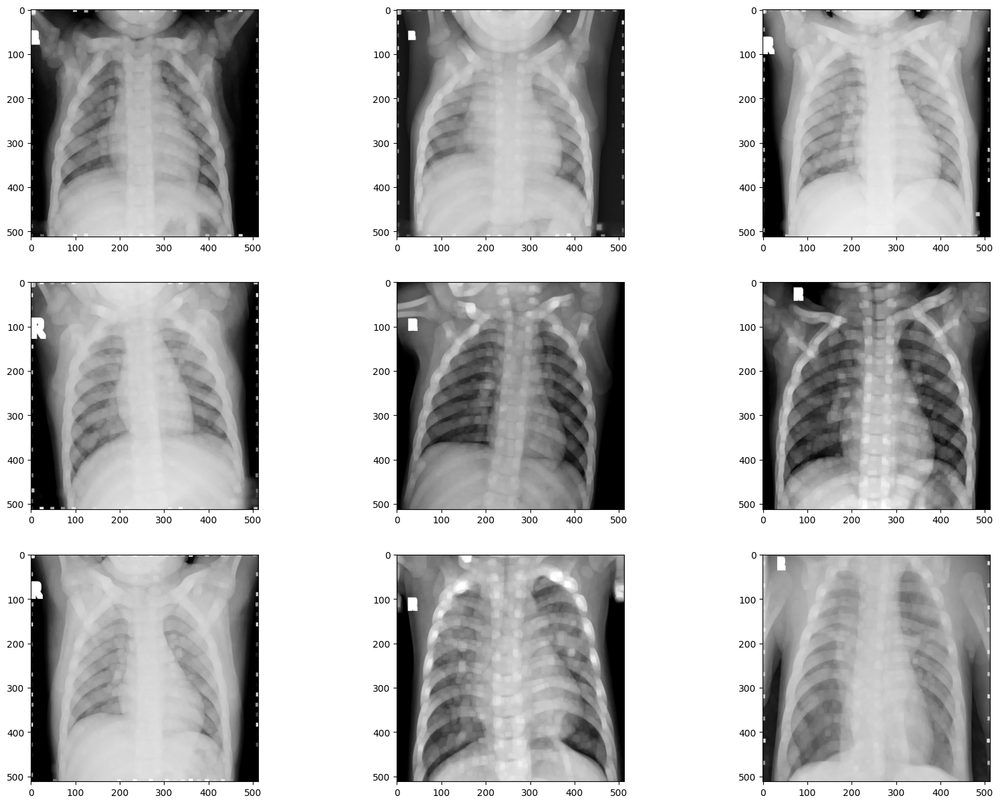

In [14]:
fig = plt.figure(figsize=(20, 15))
columns, rows = 3, 3

for i in range(1, 10):
  img = cv2.imread(images[i])
  img = cv2.resize(img, (512, 512))
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  kernel = np.ones((5, 5), np.uint8)
  image_dilation = cv2.dilate(img, kernel, iterations = 2)
  fig.add_subplot(rows, columns, i)
  plt.imshow(image_dilation)

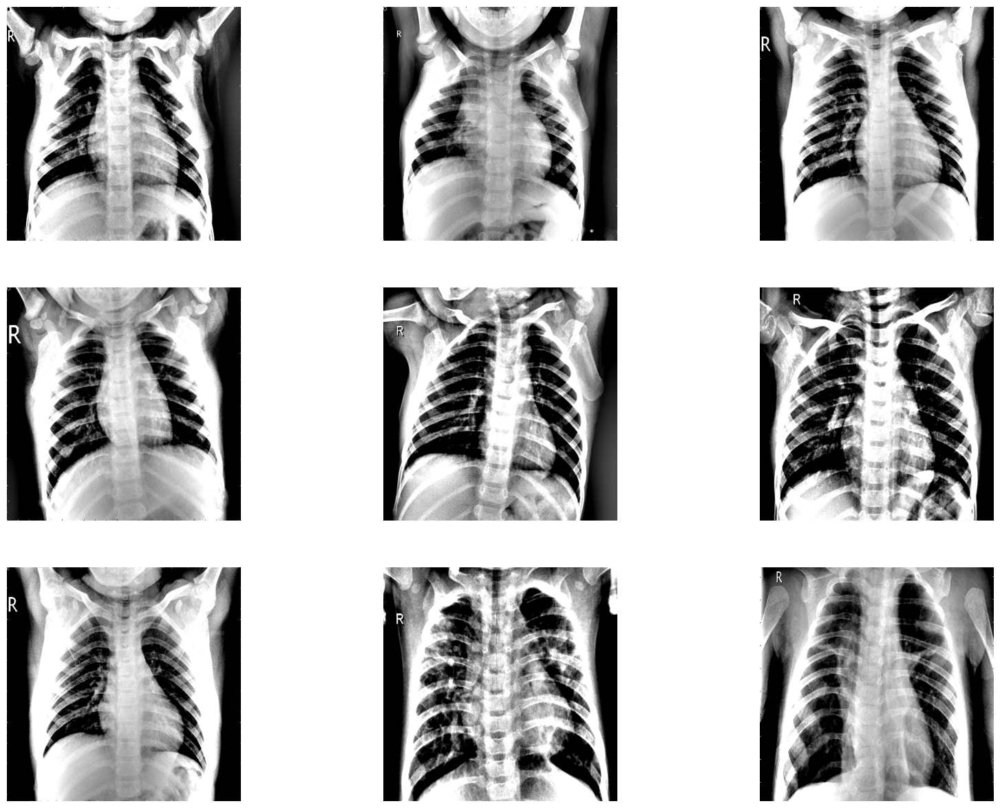

In [15]:
fig = plt.figure(figsize=(20, 15))
columns, rows = 3, 3

for i in range(1, 10):
  img = cv2.imread(images[i])
  img = cv2.resize(img, (512, 512))
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  img = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), 512 / 10), -4, 128)
  fig.add_subplot(rows, columns, i)
  plt.imshow(img)
  plt.axis(False)

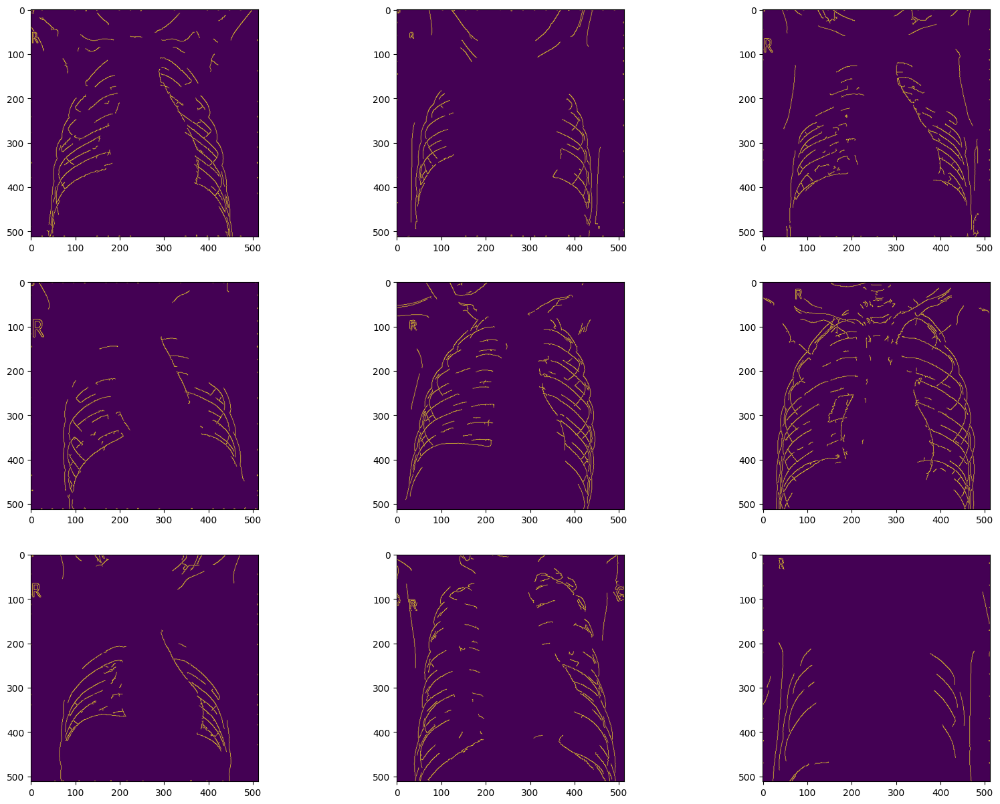

In [16]:
fig = plt.figure(figsize = (20, 15))
columns, rows = 3, 3

for i in range (1, 10):
  img = cv2.imread(images[i])
  img = cv2.resize(img, (512, 512))
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  detected_edges = cv2.Canny(img, 100, 200)
  fig.add_subplot(rows, columns, i)
  plt.imshow(detected_edges)

In [17]:
train_dir = '/content/chest-xray-pneumonia/chest_xray/chest_xray/train'
test_dir = '/content/chest-xray-pneumonia/chest_xray/chest_xray/test'
val_dir = '/content/chest-xray-pneumonia/chest_xray/chest_xray/val'

In [18]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
train_datagen = ImageDataGenerator(
    rescale = 1/255.,
    horizontal_flip = True,
    vertical_flip = True,
    rotation_range = 0.2,
    zca_whitening = True,
    width_shift_range = 0.25,
    height_shift_range = 0.25,
    channel_shift_range = 0.35,
    shear_range = 0.2,
    zoom_range = 0.4
)

val_test_datagen = ImageDataGenerator(
    rescale = 1./255
)

/usr/local/lib/python3.13/dist-packages/keras/src/legacy/preprocessing/image.py:1045: UserWarning:

This ImageDataGenerator specifies `zca_whitening`, which overrides setting of `featurewise_center`.



In [19]:
train_set = train_datagen.flow_from_directory(
    train_dir,
    class_mode = 'binary',
    batch_size = 32,
    target_size = (224, 224)
)
test_set = train_datagen.flow_from_directory(
    test_dir,
    class_mode = 'binary',
    batch_size = 32,
    target_size = (224, 224)
)
val_set = val_test_datagen.flow_from_directory(
    val_dir,
    class_mode = 'binary',
    batch_size = 32,
    target_size = (224, 224)
)

Found 5216 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Found 16 images belonging to 2 classes.


In [20]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from keras.models import Sequential


In [21]:
model = Sequential()

model.add(Conv2D(32, (3, 3), strides = (1, 1), activation = 'relu', padding = 'same', input_shape = (224, 224, 3)))
model.add(MaxPooling2D(pool_size = (2, 2)))
model.add(Conv2D(64, (3, 3), strides = (1, 1), padding = 'same', activation = 'relu'))
model.add(MaxPooling2D(pool_size = (2, 2)))
model.add(Dropout(0.2))
model.add(Conv2D(128, (3, 3), strides = (1, 1), padding = 'same', activation = 'relu'))
model.add(MaxPooling2D(pool_size = (2, 2)))
model.add(Conv2D(256, (3, 3), strides = (1, 1), padding = 'same', activation = "relu"))
model.add(MaxPooling2D(pool_size = (2, 2)))
model.add(Dropout(0.2))

model.add(Flatten())

model.add(Dense(128, activation = 'relu'))
model.add(Dense(64, activation = 'relu'))
model.add(Dense(32, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))



/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [22]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,821,441 (26.02 MB)

 Trainable params: 6,821,441 (26.02 MB)

 Non-trainable params: 0 (0.00 B)

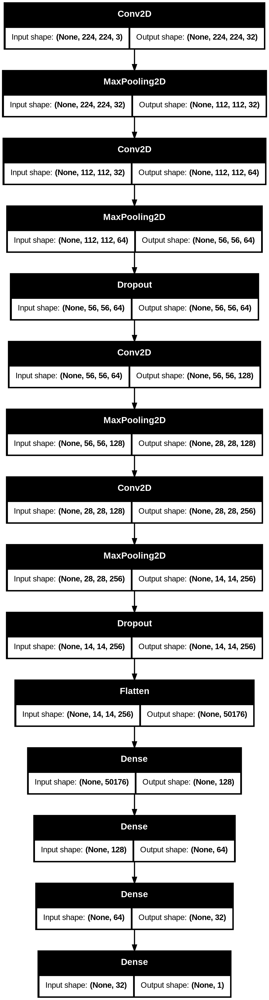

In [23]:
from keras.utils import plot_model
plot_model(model, show_shapes= True)

In [24]:
model.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [25]:
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.applications.vgg16 import VGG16

In [26]:
early_stopping_callbacks = tensorflow.keras.callbacks.EarlyStopping(
    patience = 15,
    restore_best_weights = True,
    verbose = 1
)

In [27]:
history = model.fit(
    train_set,
    epochs = 20, validation_data=val_set,
    steps_per_epoch= 100,
    callbacks = [early_stopping_callbacks]
)


/usr/local/lib/python3.13/dist-packages/keras/src/legacy/preprocessing/image.py:1261: UserWarning:

This ImageDataGenerator specifies `featurewise_center`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.

/usr/local/lib/python3.13/dist-packages/keras/src/legacy/preprocessing/image.py:1284: UserWarning:

This ImageDataGenerator specifies `zca_whitening`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.



Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 92s 771ms/step - accuracy: 0.7487 - loss: 0.4998 - val_accuracy: 0.6250 - val_loss: 0.6237
Epoch 2/20
 63/100 ━━━━━━━━━━━━━━━━━━━━ 26s 719ms/step - accuracy: 0.7986 - loss: 0.4166

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning:

Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.



100/100 ━━━━━━━━━━━━━━━━━━━━ 45s 453ms/step - accuracy: 0.7907 - loss: 0.4269 - val_accuracy: 0.7500 - val_loss: 0.5972
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 76s 758ms/step - accuracy: 0.8075 - loss: 0.3808 - val_accuracy: 0.5625 - val_loss: 0.7944
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 46s 463ms/step - accuracy: 0.8294 - loss: 0.3747 - val_accuracy: 0.5625 - val_loss: 1.1161
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 74s 741ms/step - accuracy: 0.8341 - loss: 0.3442 - val_accuracy: 0.5625 - val_loss: 0.7828
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 46s 457ms/step - accuracy: 0.8512 - loss: 0.3132 - val_accuracy: 0.6250 - val_loss: 1.0184
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 76s 757ms/step - accuracy: 0.8547 - loss: 0.3290 - val_accuracy: 0.7500 - val_loss: 0.5923
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 46s 462ms/step - accuracy: 0.8596 - loss: 0.3129 - val_accuracy: 0.6250 - val_loss: 0.7879
Epoch 9/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 78s 778ms/step - accuracy: 0.8631 - loss: 0.2945 - val

In [28]:
model.inputs, model.outputs

([<KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor>],
 [<KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=keras_tensor_120>])

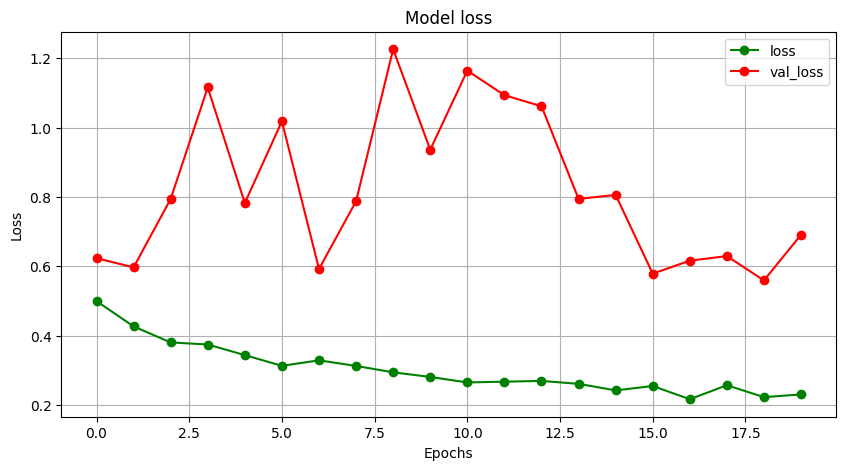

In [29]:
plt.figure(figsize = (10, 5))
plt.title('Model loss')
plt.plot(history.history['loss'], 'go-')
plt.plot(history.history['val_loss'], 'ro-')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(['loss', 'val_loss'])
plt.grid(True)
plt.show()

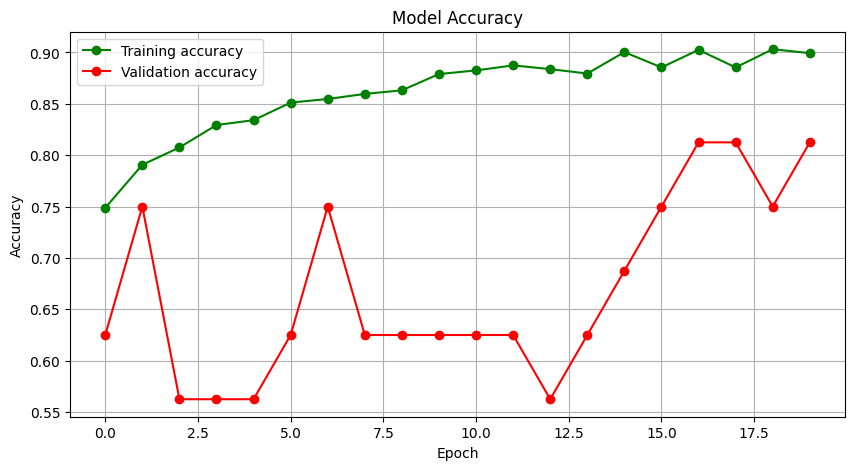

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], 'go-', label='Training accuracy')
plt.plot(history.history['val_accuracy'], 'ro-', label='Validation accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [31]:
test_loss, test_accuracy = model.evaluate(test_set, verbose=1)

print('The testing accuracy is:', test_accuracy * 100, '%')
print('The testing loss is:', test_loss * 100, "%")

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 646ms/step - accuracy: 0.8494 - loss: 0.3562
The testing accuracy is: 84.93589758872986 %
The testing loss is: 35.62411367893219 %


In [ ]:
from tensorflow.keras.applications.vgg16 import VGG16

In [33]:
base_model = VGG16(include_top = False, weights='imagenet',  input_shape = (224, 224, 3), pooling='max', classes = 2)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [ ]:
base_model.summary()

In [35]:
model1 = Sequential()

model1.add(base_model)
model1.add(Flatten())

model1.add(Dense(128, activation = 'relu'))
model1.add(Dense(64, activation = 'relu'))
model1.add(Dense(32, activation = 'relu'))
model1.add(Dense(1, activation = 'sigmoid'))

In [36]:
model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 512)            │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,790,721 (56.42 MB)

 Trainable params: 14,790,721 (56.42 MB)

 Non-trainable params: 0 (0.00 B)

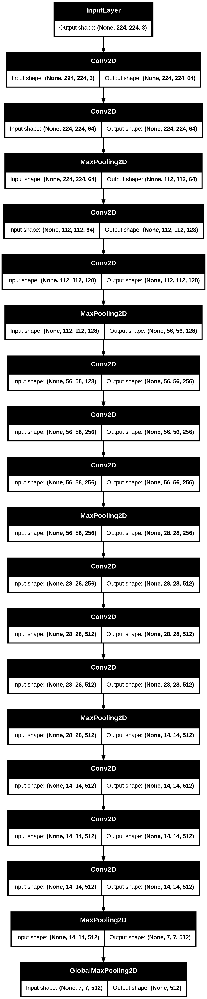

In [37]:
plot_model(base_model, show_shapes=True)

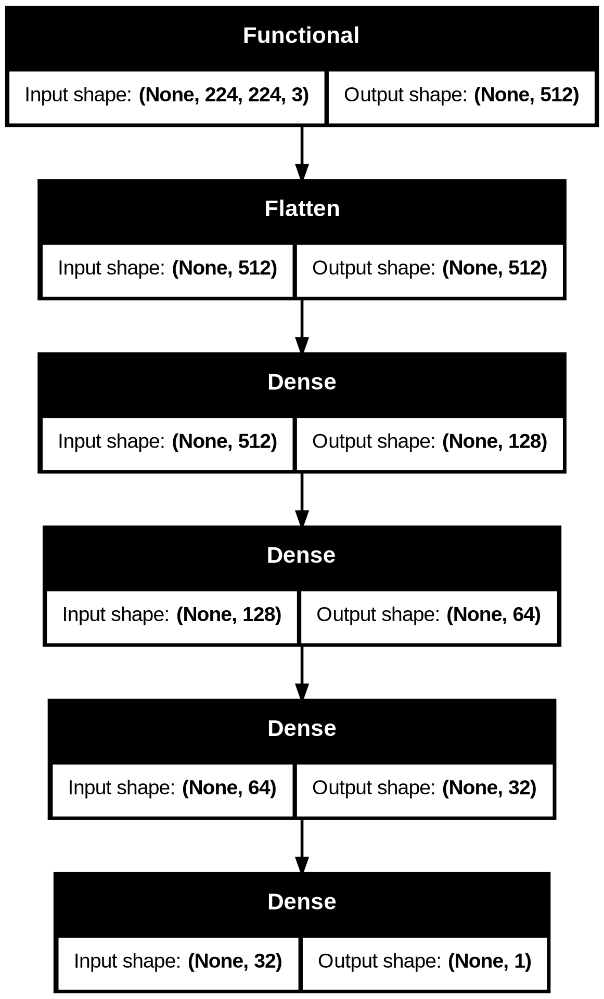

In [38]:
plot_model(model1, show_shapes = True)

In [39]:
for layer in base_model.layers:
  layer.trainable = False

In [40]:
from keras.src.optimizers import optimizer
model1.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['Accuracy'])

In [41]:
history = model1.fit(
    train_set,
    epochs = 20,
    validation_data=val_set,
    steps_per_epoch= 100,
    callbacks = [early_stopping_callbacks]
)

/usr/local/lib/python3.13/dist-packages/keras/src/legacy/preprocessing/image.py:1261: UserWarning:

This ImageDataGenerator specifies `featurewise_center`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.

/usr/local/lib/python3.13/dist-packages/keras/src/legacy/preprocessing/image.py:1284: UserWarning:

This ImageDataGenerator specifies `zca_whitening`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.



Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 86s 794ms/step - Accuracy: 0.8372 - loss: 0.3538 - val_Accuracy: 0.7500 - val_loss: 0.4052
Epoch 2/20
 63/100 ━━━━━━━━━━━━━━━━━━━━ 27s 748ms/step - Accuracy: 0.8796 - loss: 0.2776

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning:

Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.



100/100 ━━━━━━━━━━━━━━━━━━━━ 47s 472ms/step - Accuracy: 0.8829 - loss: 0.2776 - val_Accuracy: 0.7500 - val_loss: 0.5812
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 88s 766ms/step - Accuracy: 0.8897 - loss: 0.2653 - val_Accuracy: 0.7500 - val_loss: 0.7041
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 48s 476ms/step - Accuracy: 0.9048 - loss: 0.2384 - val_Accuracy: 0.7500 - val_loss: 0.6257
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 76s 764ms/step - Accuracy: 0.8913 - loss: 0.2523 - val_Accuracy: 0.6875 - val_loss: 0.9507
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 48s 484ms/step - Accuracy: 0.9033 - loss: 0.2259 - val_Accuracy: 0.7500 - val_loss: 0.7338
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 77s 763ms/step - Accuracy: 0.9038 - loss: 0.2253 - val_Accuracy: 0.7500 - val_loss: 0.7500
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 48s 477ms/step - Accuracy: 0.8998 - loss: 0.2370 - val_Accuracy: 0.6875 - val_loss: 0.4960
Epoch 9/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 76s 761ms/step - Accuracy: 0.9091 - loss: 0.2225 - val

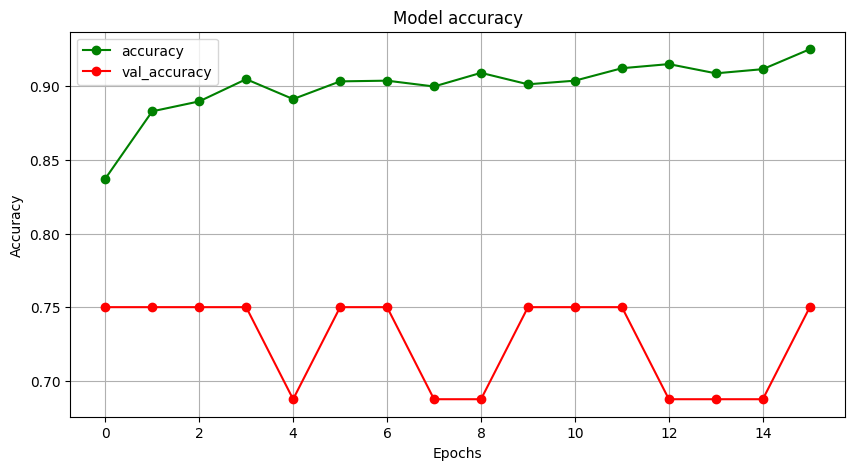

In [42]:
plt.figure(figsize = (10, 5))
plt.title('Model accuracy')
plt.plot(history.history['Accuracy'], 'go-')
plt.plot(history.history['val_Accuracy'], 'ro-')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(['accuracy', 'val_accuracy'])
plt.grid(True)
plt.show()

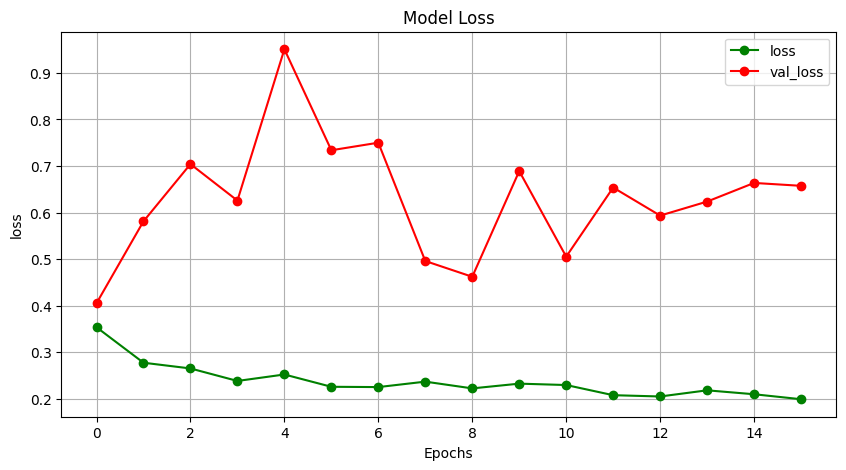

In [43]:
from jax.tree_util import tree_reduce
plt.figure(figsize = (10, 5))
plt.title('Model Loss')
plt.plot(history.history['loss'], 'go-')
plt.plot(history.history['val_loss'], 'ro-')
plt.ylabel('loss')
plt.xlabel('Epochs')
plt.legend(['loss', 'val_loss'])
plt.grid(True)
plt.show()

In [44]:
test_loss, test_accuracy = model1.evaluate(test_set, verbose = 1)
print('The testing accuracy is:', test_accuracy * 100, '%')
print('The testing loss is:', test_loss * 100, '%')

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 689ms/step - Accuracy: 0.7997 - loss: 0.4024
The testing accuracy is: 79.96794581413269 %
The testing loss is: 40.242910385131836 %


In [45]:
from tensorflow.keras.applications import ResNet50V2

In [46]:
base_model1 = ResNet50V2(weights='imagenet',
                         input_shape=(224, 224, 3),
                         pooling = 'max',
                         include_top = False,
                         classes = 2)

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


In [47]:
base_model1.summary()

Model: "resnet50v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_3[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_conv[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 56, 56,    │        256 │ pool1_pool[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 56, 56,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 58, 58,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_pre… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 56, 56,    │          0 │ conv2_block1_0_c

 Total params: 23,564,800 (89.89 MB)

 Trainable params: 23,519,360 (89.72 MB)

 Non-trainable params: 45,440 (177.50 KB)

In [48]:
plot_model(base_model1, show_shapes=True)

In [49]:
model2 = Sequential()

model2.add(base_model1)

model2.add(Flatten())
model2.add(Dense(128, activation = 'relu'))
model2.add(Dense(64, activation  = 'relu'))
model2.add(Dense(32, activation = 'relu'))
model2.add(Dense(1, activation = 'sigmoid'))

In [50]:
model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 2048)           │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,837,441 (90.93 MB)

 Trainable params: 23,792,001 (90.76 MB)

 Non-trainable params: 45,440 (177.50 KB)

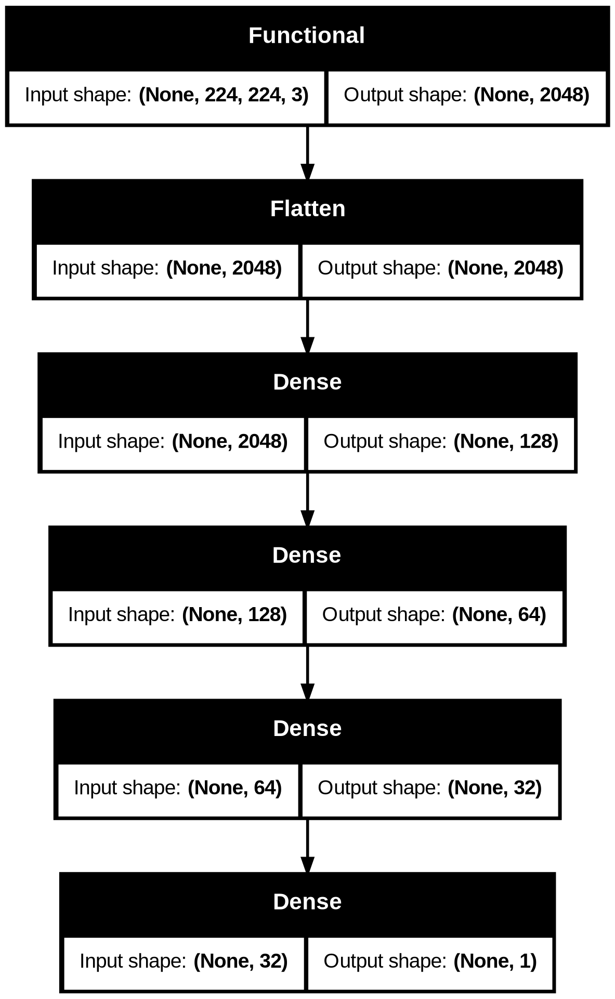

In [51]:
plot_model(model2, show_shapes=True)

In [52]:
for layer in base_model1.layers:
  layer.trainable = False

In [53]:
model2.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [54]:
history = model2.fit(
    train_set,
    epochs = 20,
    validation_data = val_set,
    steps_per_epoch=100,
    callbacks = [early_stopping_callbacks]
)

/usr/local/lib/python3.13/dist-packages/keras/src/legacy/preprocessing/image.py:1261: UserWarning:

This ImageDataGenerator specifies `featurewise_center`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.

/usr/local/lib/python3.13/dist-packages/keras/src/legacy/preprocessing/image.py:1284: UserWarning:

This ImageDataGenerator specifies `zca_whitening`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.



Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 92s 798ms/step - accuracy: 0.8547 - loss: 0.3537 - val_accuracy: 0.7500 - val_loss: 0.6639
Epoch 2/20
 63/100 ━━━━━━━━━━━━━━━━━━━━ 27s 730ms/step - accuracy: 0.8719 - loss: 0.3175

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning:

Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.



100/100 ━━━━━━━━━━━━━━━━━━━━ 46s 463ms/step - accuracy: 0.8834 - loss: 0.2795 - val_accuracy: 0.9375 - val_loss: 0.3226
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 79s 788ms/step - accuracy: 0.9078 - loss: 0.2145 - val_accuracy: 0.8750 - val_loss: 0.3392
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 49s 497ms/step - accuracy: 0.9097 - loss: 0.2214 - val_accuracy: 0.8750 - val_loss: 0.2842
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 79s 785ms/step - accuracy: 0.9291 - loss: 0.1791 - val_accuracy: 0.9375 - val_loss: 0.4131
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 49s 486ms/step - accuracy: 0.9201 - loss: 0.2044 - val_accuracy: 0.8750 - val_loss: 0.3401
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 77s 766ms/step - accuracy: 0.9397 - loss: 0.1620 - val_accuracy: 0.8125 - val_loss: 0.4319
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 49s 489ms/step - accuracy: 0.9246 - loss: 0.1882 - val_accuracy: 0.8750 - val_loss: 0.4124
Epoch 9/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 78s 775ms/step - accuracy: 0.9259 - loss: 0.1780 - val

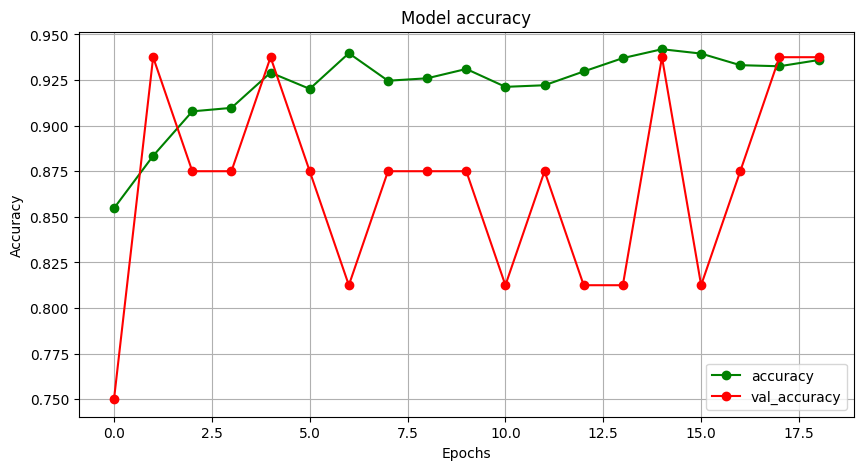

In [55]:
plt.figure(figsize=(10, 5))
plt.title('Model accuracy')
plt.plot(history.history['accuracy'], 'go-')
plt.plot(history.history['val_accuracy'], 'ro-')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(['accuracy', 'val_accuracy'])
plt.grid(True)
plt.show()

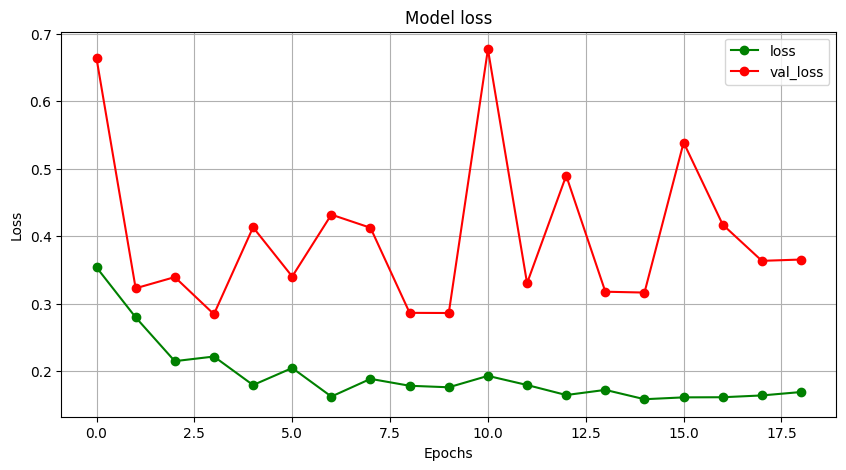

In [56]:
plt.figure(figsize = (10, 5))
plt.title('Model loss')
plt.plot(history.history['loss'], 'go-')
plt.plot(history.history['val_loss'], 'ro-')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(['loss', 'val_loss'])
plt.grid(True)
plt.show()

In [57]:
test_loss, test_accuracy = model2.evaluate(test_set, verbose = 1)
print('The testing accuracy is:', test_accuracy * 100, '%')
print('The testing loss is: ', test_loss * 100, '%')

20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 697ms/step - accuracy: 0.8670 - loss: 0.3369
The testing accuracy is: 86.69871687889099 %
The testing loss is:  33.68642330169678 %


In [59]:
from tensorflow.keras.preprocessing import image
new_image_path = '/content/pneumonia.webp'
test_image = image.load_img(new_image_path, target_size = (224, 224))
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)
test_image = test_image / 255

result = model2.predict(test_image)
train_set.class_indices
if result [0][0] == 0:
  prediction = 'Norml'

else:
  prediction = 'Pneumonia'
print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Pneumonia


In [62]:
model2.save("my pneumonia detection model.h5")
print(colored('Model3 was succesfully saved to the disk...', color = 'green', attrs = ['bold', 'dark']))

Model3 was succesfully saved to the disk...


In [63]:
model_loaded = tensorflow.keras.models.load_model('/content/my pneumonia detection model.h5')


In [64]:
model_loaded.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 2048)           │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,837,443 (90.93 MB)

 Trainable params: 272,641 (1.04 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

 Optimizer params: 2 (12.00 B)

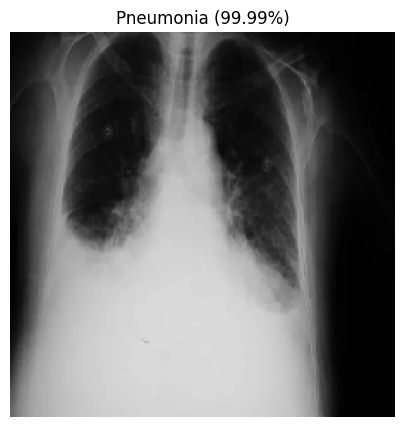

Prediction: Pneumonia
Score: 99.99%


In [65]:
import tensorflow as tf
def image_prediction(new_image_path):
    # Load and preprocess the image
    test_image = load_img(new_image_path, target_size=(224, 224))
    test_array = img_to_array(test_image)
    test_array = np.expand_dims(test_array, axis=0) / 255.0

    # Load your trained model
    model_loaded = tf.keras.models.load_model(
        '/content/my pneumonia detection model.h5'
    )

    # Predict
    prediction = model_loaded.predict(test_array, verbose=0)
    score = float(np.ravel(prediction)[0])

    # Display the image
    plt.figure(figsize=(5, 5))
    plt.imshow(test_image)
    plt.axis('off')

    if score > 0.5:
        label = 'Pneumonia'
        confidence = score * 100
    else:
        label = 'Normal'
        confidence = (1 - score) * 100

    plt.title(f'{label} ({confidence:.2f}%)')
    plt.show()

    print(f'Prediction: {label}')
    print(f'Score: {confidence:.2f}%')

# Use the correct path for your image
image_prediction('/content/pneumonia1.webp')

In [66]:
test_dir = '/content/chest-xray-pneumonia/chest_xray/chest_xray/test'
test_data, test_labels = [], []

In [67]:
test_dirs = [
    '/content/chest-xray-pneumonia/chest_xray/chest_xray/test/NORMAL',
    '/content/chest-xray-pneumonia/chest_xray/chest_xray/test/PNEUMONIA'
]

for folder in test_dirs:
    for filename in os.listdir(folder):
        image_path = os.path.join(folder, filename)

        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        if image is None:
            continue

        image = cv2.resize(image, (224, 224))
        image = image.astype('float32') / 255.0

        # Repeat grayscale channel to create 3 channels
        image = np.stack([image, image, image], axis=-1)

        label = 0 if os.path.basename(folder) == 'NORMAL' else 1

        test_data.append(image)
        test_labels.append(label)

test_data = np.array(test_data)
test_labels = np.array(test_labels)

print("Test data shape:", test_data.shape)
print("Test labels shape:", test_labels.shape)

Test data shape: (624, 224, 224, 3)
Test labels shape: (624,)


In [70]:
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step
Testing accuracy: 89.26 %
TN: 215 FP: 19 FN: 48 TP: 342


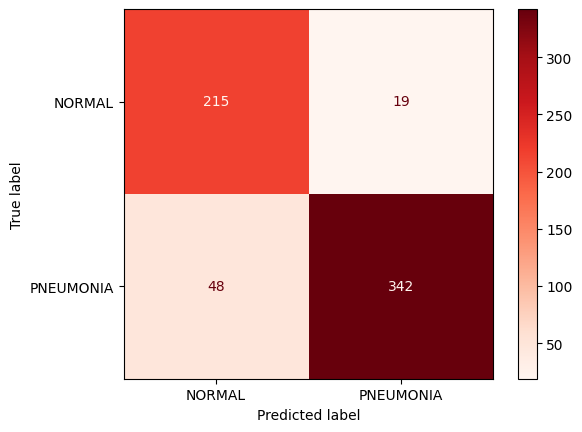

In [72]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import numpy as np

predictions = model_loaded.predict(test_data)

# Convert probabilities to class labels
predicted_labels = (predictions.ravel() >= 0.5).astype(int)

conf_m = confusion_matrix(test_labels, predicted_labels)
acc = accuracy_score(test_labels, predicted_labels) * 100

tn, fp, fn, tp = conf_m.ravel()

print("Testing accuracy:", round(acc, 2), "%")
print("TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_m,
    display_labels=["NORMAL", "PNEUMONIA"]
)
disp.plot(cmap=plt.cm.Reds, values_format="d")
plt.show()

In [74]:
# Calculate evaluation metrics
precision = tp / (tp + fp) * 100 if (tp + fp) != 0 else 0
recall = tp / (tp + fn) * 100 if (tp + fn) != 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) != 0 else 0
)

print('Accuracy: {:.2f}%'.format(acc))
print('Precision: {:.2f}%'.format(precision))
print('Recall: {:.2f}%'.format(recall))
print('F1-score: {:.2f}%'.format(f1_score))

Accuracy: 89.26%
Precision: 94.74%
Recall: 87.69%
F1-score: 91.08%


In [76]:
predictions = list()
preds = model_loaded.predict(test_data)
for i in preds:
  if i >= 0.5:
    predictions.append(1)
  else:
    predictions.append(0)
predictions[: 15]

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step


[0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

In [77]:
correct_predictions = np.nonzero(predictions == test_labels)[0]
incorrect_predictions = np.nonzero(predictions != test_labels)[0]

print('Indices of the correct predictions: \n', correct_predictions[:15])
print('Indices of the incorrect predictions: \n', incorrect_predictions[:15])

Indices of the correct predictions: 
 [ 0  1  2  4  5  6  7  8  9 10 11 12 13 14 15]
Indices of the incorrect predictions: 
 [  3  21  60  69  74  87  93  96  99 101 102 116 122 152 159]


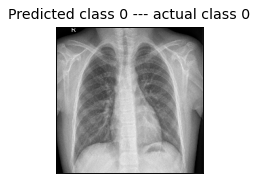

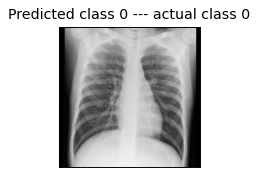

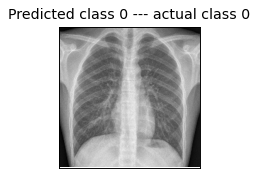

In [78]:
# display correct predictions

i = 0
for a in correct_predictions[:3]:
  plt.figure(figsize=(8, 6), dpi = 85)
  plt.subplot(3, 1, i + 1)
  plt.xticks([]), plt.yticks([])
  plt.imshow(test_data[a].reshape(224, 224, 3))
  plt.title('Predicted class {} --- actual class {}'.format(predictions[a], test_labels[a]))
  plt.tight_layout()
  i += 1

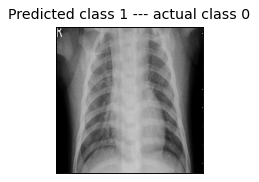

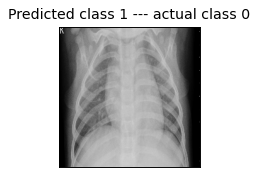

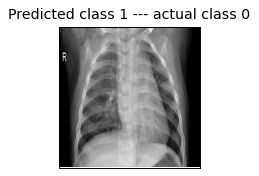

In [79]:
# display the incorrect predictions

i = 0
for a in incorrect_predictions[:3]:
  plt.figure(figsize = (8, 6), dpi = 85)
  plt.subplot(3, 1, i + 1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(test_data[a].reshape(224, 224, 3))
  plt.title('Predicted class {} --- actual class {}'.format(predictions[a], test_labels[a]))
  plt.tight_layout()
  i += 1